### ⚙️ Tahap 1: Preparation & Load Dataset
Cell ini memuat pustaka-pustaka Python yang dibutuhkan dan mengimpor dataset BPS.

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 1 (Data Understanding):** Sumber data & lisensi/izin (BPS RI / Public Domain)[cite: 12, 28].

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE

# Pengaturan tampilan Pandas
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

# Setting Tampilan Grafik Plot
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# Load Dataset
df = pd.read_csv('Klasifikasi Tingkat Kemiskinan di Indonesia.csv')
target = 'Klasifikasi Kemiskinan'

print(f"✅ Dataset berhasil dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.\n")

✅ Dataset berhasil dimuat: 514 baris, 13 kolom.



---
### 📖 Tahap 2: Data Dictionary & Data Profiling

Memetakan variabel, tipe data, satuan/unit, dan rentang nilai (Min-Max) untuk memahami struktur dataset[cite: 12, 13].

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 2 (Data Understanding):** Data dictionary (variabel, tipe, unit).

In [101]:
# Pemetaan unit/satuan secara eksplisit
units = {
    'Provinsi': 'Nama Teks',
    'Kab/Kota': 'Nama Teks',
    'Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)': 'Persen (%)',
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)': 'Tahun',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)': 'Ribu Rp/Orang/Th',
    'Indeks Pembangunan Manusia': 'Indeks (0-100)',
    'Umur Harapan Hidup (Tahun)': 'Tahun',
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak': 'Persen (%)',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak': 'Persen (%)',
    'Tingkat Pengangguran Terbuka': 'Persen (%)',
    'Tingkat Partisipasi Angkatan Kerja': 'Persen (%)',
    'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)': 'Rupiah',
    'Klasifikasi Kemiskinan': 'Binary (0 / 1)'
}

data_dict = []
for col in df.columns:
    is_numeric = np.issubdtype(df[col].dtype, np.number)
    data_dict.append({
        'Nama Variabel': col,
        'Tipe Data': str(df[col].dtype),
        'Satuan/Unit': units.get(col, '-'),
        'Nilai Min': df[col].min() if is_numeric else '-',
        'Nilai Max': df[col].max() if is_numeric else '-'
    })

df_data_dictionary = pd.DataFrame(data_dict)
print("=== DATA DICTIONARY DATASET ===")
print(df_data_dictionary.to_string(index=False))

=== DATA DICTIONARY DATASET ===
                                                       Nama Variabel Tipe Data      Satuan/Unit Nilai Min Nilai Max
                                                            Provinsi    object        Nama Teks         -         -
                                                            Kab/Kota    object        Nama Teks         -         -
     Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)   float64       Persen (%)      2.38     41.66
                         Rata-rata Lama Sekolah Penduduk 15+ (Tahun)   float64            Tahun      1.42     12.83
        Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)     int64 Ribu Rp/Orang/Th      3976     23888
                                          Indeks Pembangunan Manusia   float64   Indeks (0-100)     32.84     87.18
                                          Umur Harapan Hidup (Tahun)   float64            Tahun     55.43     77.73
 Persentase rumah tangga yang memiliki a

---
### 🔍 Tahap 3: Audit Kualitas Data & Statistik Deskriptif

Melakukan pengecekan menyeluruh terhadap ketersediaan data hilang (*missing values*), duplikasi baris, *outliers* dengan metode IQR (1.5x IQR), serta ringkasan statistik deskriptif.

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 3 (Data Understanding):** Kualitas data (missing, outlier, duplikasi).
  * **Aspek 6:** Statistik deskriptif ditampilkan dan disimpulkan.
  * **Aspek 9 (Audit kualitas data):** Menghitung dan analisis missing value, outlier, dan duplikat tiap kolom.

In [102]:

# 1. Audit Missing Values dan Duplikasi

total_missing = df.isnull().sum().sum()
total_sel = df.shape[0] * df.shape[1]
persentase_missing = (total_missing / total_sel) * 100

duplicate_count = df.duplicated().sum()

print("=" * 70)
print("AUDIT MISSING VALUE DAN DUPLIKASI")
print("=" * 70)

print(f"Total Missing Value : {total_missing}")
print(f"Persentase Missing  : {persentase_missing:.2f}%")
print(f"Total Baris Duplikat: {duplicate_count}")

# Audit per kolom
audit = pd.DataFrame({
    'Missing Value': df.isnull().sum(),
    'Persentase Missing (%)': (df.isnull().mean() * 100).round(2),
    'Jumlah Nilai Unik': df.nunique(),
    'Tipe Data': df.dtypes.astype(str)
})

print("\n--- Audit Per Kolom ---")
print(audit.to_string())

# 2. Audit Outlier menggunakan IQR

numeric_cols = df.drop(
    columns=[target]
).select_dtypes(include=np.number).columns

outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        'Fitur': col,
        'Jumlah Outlier': jumlah_outlier,
        'Persentase Outlier (%)': round(
            jumlah_outlier / len(df) * 100, 2
        )
    })

df_outliers = pd.DataFrame(outlier_results)

print("\n--- Audit Outlier (Metode IQR) ---")
print(df_outliers.to_string(index=False))

# 3. Statistik Deskriptif

statistik = df[numeric_cols].describe().T[
    ['mean', 'std', 'min', '50%', 'max']
].round(2)

statistik.columns = [
    'Rata-rata',
    'Standar Deviasi',
    'Minimum',
    'Median',
    'Maksimum'
]

print("\n--- Statistik Deskriptif Fitur Numerik ---")
print(statistik.to_string())


AUDIT MISSING VALUE DAN DUPLIKASI
Total Missing Value : 0
Persentase Missing  : 0.00%
Total Baris Duplikat: 0

--- Audit Per Kolom ---
                                                                      Missing Value  Persentase Missing (%)  Jumlah Nilai Unik Tipe Data
Provinsi                                                                          0                     0.0                 34    object
Kab/Kota                                                                          0                     0.0                514    object
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)                   0                     0.0                451   float64
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                                       0                     0.0                351   float64
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)                      0                     0.0                498     int64
Indeks Pembangunan Manusia                 

---
### 📈 Tahap 4: Exploratory Data Analysis (EDA) Berinsight

Menganalisis distribusi variabel target, urutan korelasi fitur berdasarkan nilai mutlak (*absolute influence*), matriks korelasi *heatmap*, serta perbandingan median indikator utama per kelas[cite: 15, 16].

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 4 (Data Understanding):** EDA berinsight (distribusi/korelasi).
  * **Aspek 7 (EDA):** Visualisasi fitur dan target, beri penjelasan atas temuan.
  * **Aspek 8 (EDA):** Analisis korelasi antar fitur dan target (3 insight utama).

1. DISTRIBUSI KELAS TARGET
Non-Prioritas (0): 452 data (87.94%)
Prioritas Tinggi (1): 62 data (12.06%)


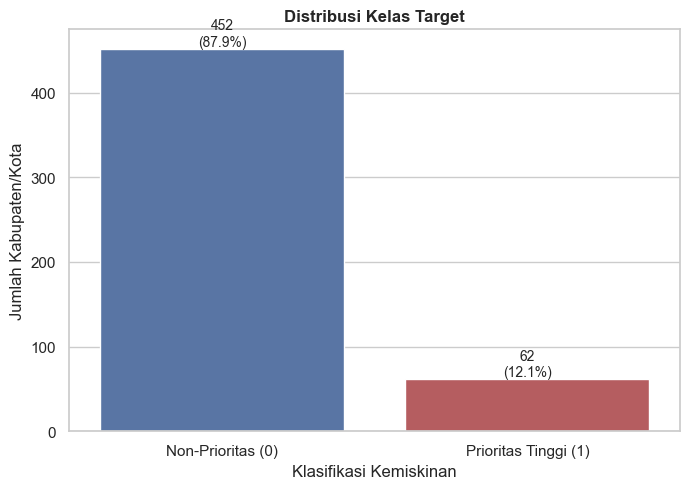


2. DISTRIBUSI FITUR NUMERIK


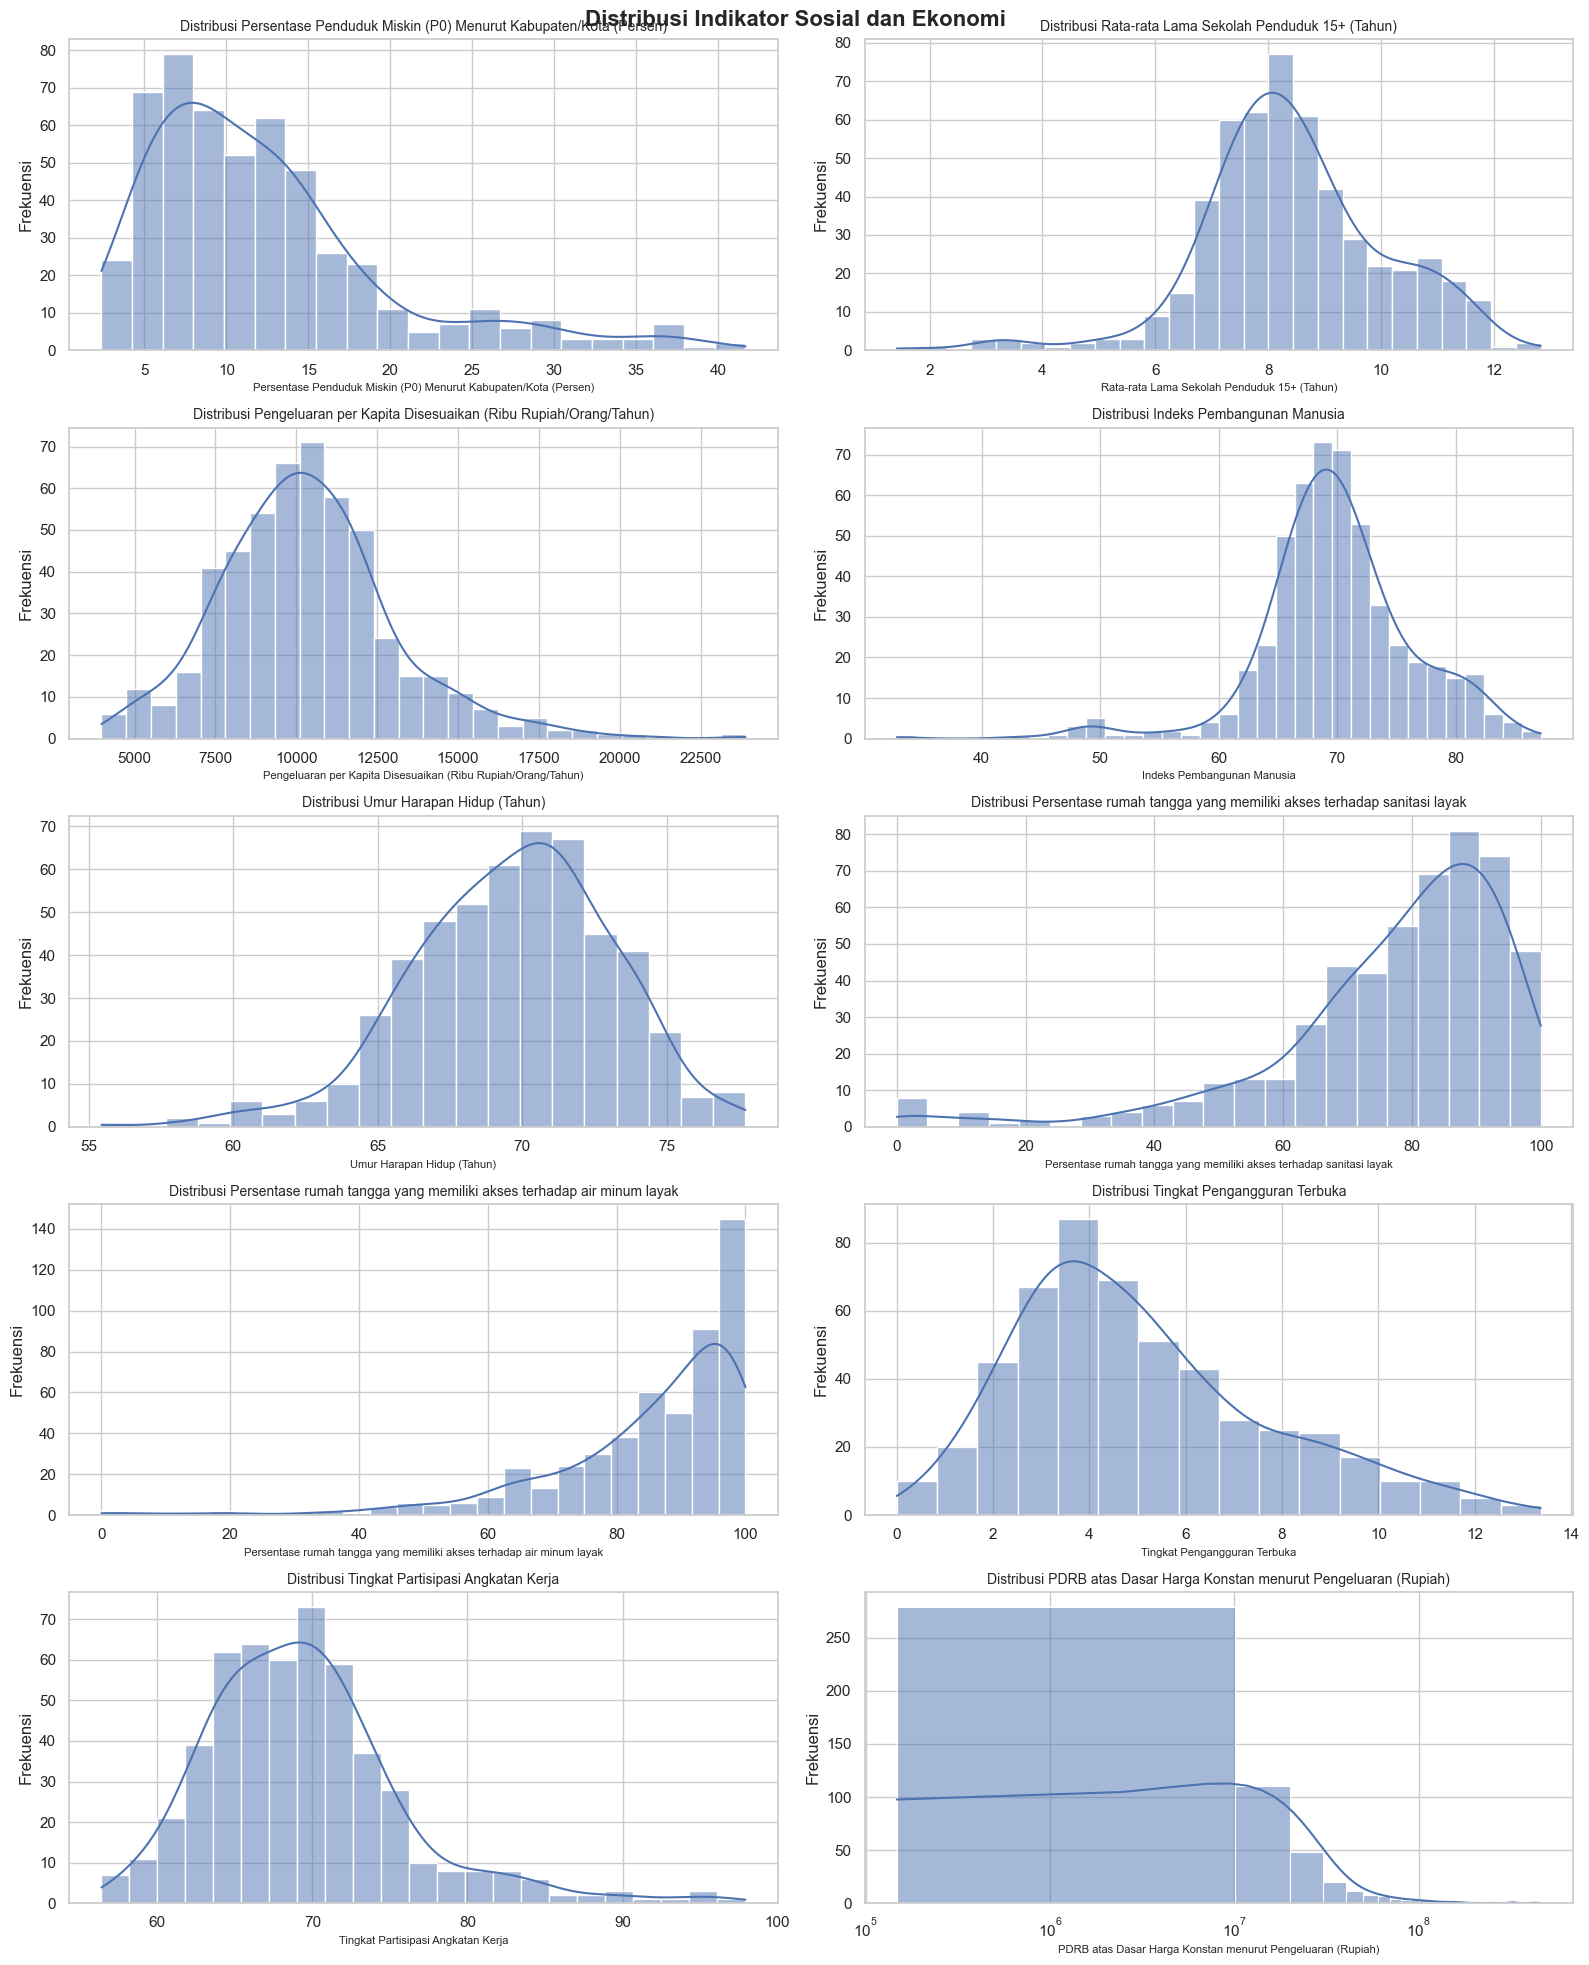


3. KORELASI FITUR TERHADAP TARGET
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)         0.756
Indeks Pembangunan Manusia                                             -0.535
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)           -0.456
Umur Harapan Hidup (Tahun)                                             -0.449
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak    -0.444
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                            -0.367
Tingkat Partisipasi Angkatan Kerja                                      0.349
Persentase rumah tangga yang memiliki akses terhadap air minum layak   -0.307
Tingkat Pengangguran Terbuka                                           -0.237
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)             -0.141


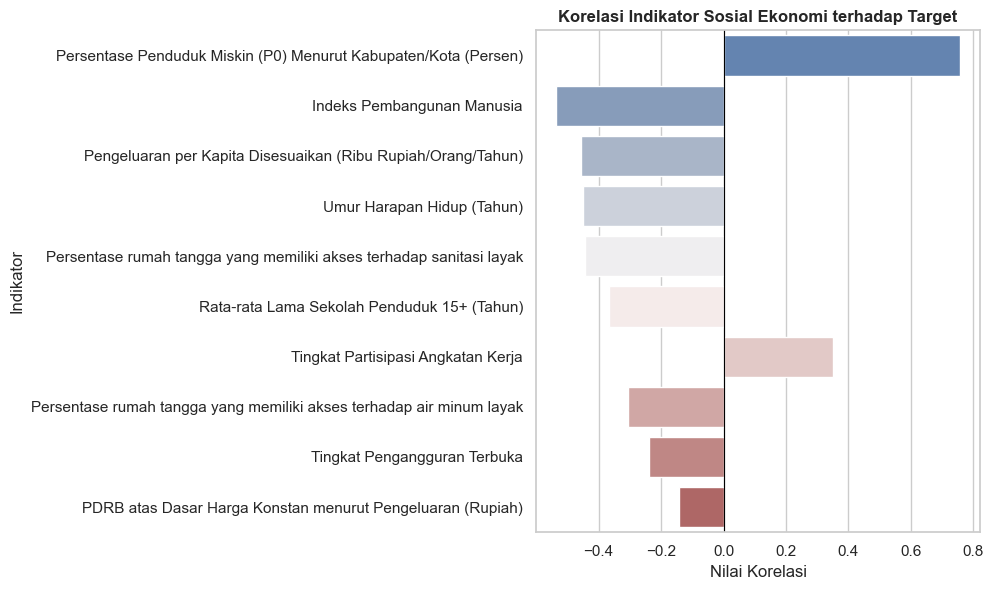

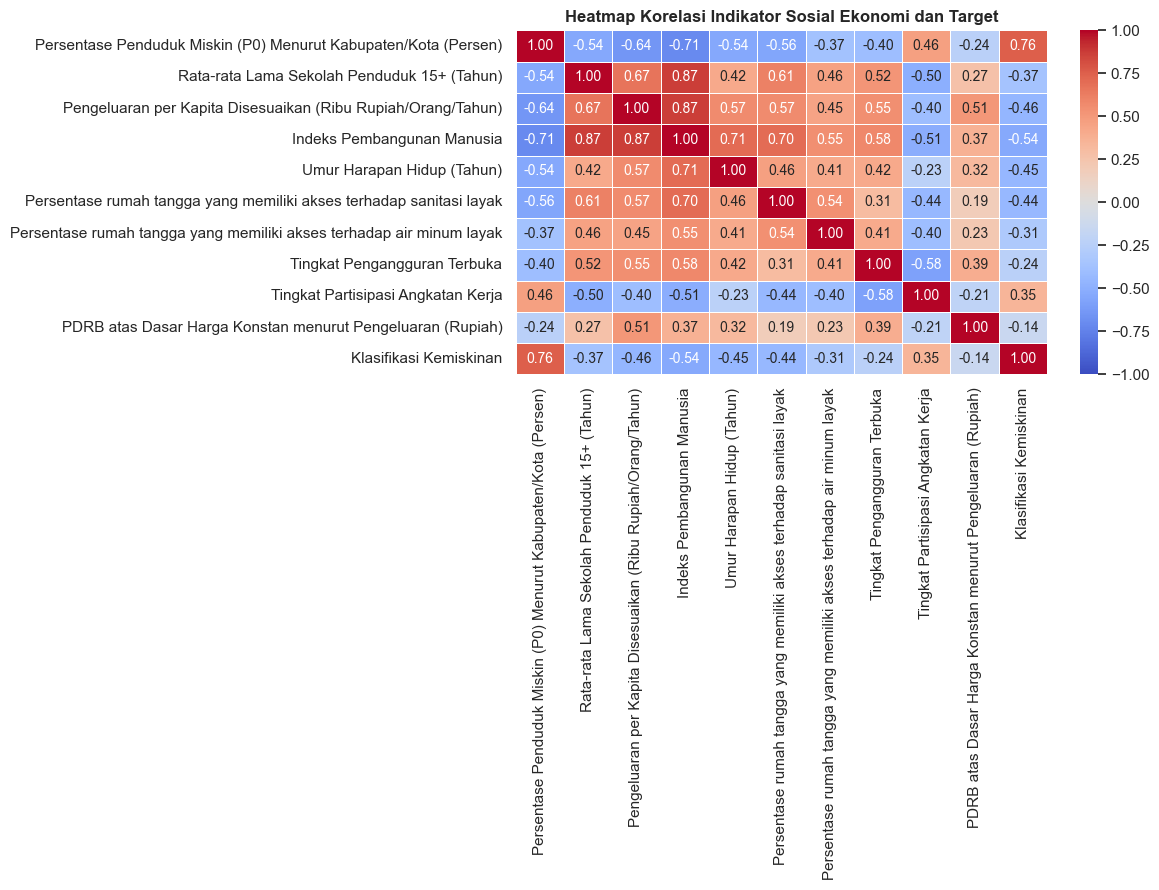


5. PERBANDINGAN MEDIAN INDIKATOR PER KELAS
                                                              Median Non-Prioritas (0)  Median Prioritas Tinggi (1)
Indeks Pembangunan Manusia                                                       70.23                        62.76
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                                       8.38                         7.08
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)                  10429.50                      6769.50

6. TIGA INSIGHT UTAMA EDA
1. Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen): korelasi 0.756 (positif) terhadap target.
2. Indeks Pembangunan Manusia: korelasi -0.535 (negatif) terhadap target.
3. Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun): korelasi -0.456 (negatif) terhadap target.

EDA selesai.


In [103]:
# ==========================================================
# TAHAP 4: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================================

# Menentukan kolom numerik dan fitur
numerik = df.select_dtypes(include=np.number)
fitur_numerik = df.drop(
    columns=[target]
).select_dtypes(include=np.number).columns


# ----------------------------------------------------------
# 1. ANALISIS DISTRIBUSI KELAS TARGET
# ----------------------------------------------------------

jumlah = df[target].value_counts().sort_index()
persentase = df[target].value_counts(normalize=True).sort_index() * 100

nama_kelas = {
    0: 'Non-Prioritas (0)',
    1: 'Prioritas Tinggi (1)'
}

print("=" * 65)
print("1. DISTRIBUSI KELAS TARGET")
print("=" * 65)

for kelas in jumlah.index:
    print(
        f"{nama_kelas.get(kelas, kelas)}: "
        f"{jumlah[kelas]} data ({persentase[kelas]:.2f}%)"
    )

# Visualisasi distribusi target
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=target,
    hue=target,
    palette=['#4c72b0', '#c44e52'],
    legend=False
)

plt.title('Distribusi Kelas Target', fontweight='bold')
plt.xlabel('Klasifikasi Kemiskinan')
plt.ylabel('Jumlah Kabupaten/Kota')
plt.xticks([0, 1], ['Non-Prioritas (0)', 'Prioritas Tinggi (1)'])

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 2. VISUALISASI DISTRIBUSI FITUR NUMERIK
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("2. DISTRIBUSI FITUR NUMERIK")
print("=" * 65)

jumlah_fitur = len(fitur_numerik)
jumlah_baris = int(np.ceil(jumlah_fitur / 2))

fig, axes = plt.subplots(
    jumlah_baris, 2,
    figsize=(16, 4 * jumlah_baris)
)

axes = np.array(axes).flatten()

for i, col in enumerate(fitur_numerik):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i],
        color='#4c72b0'
    )

    if 'PDRB' in col and (df[col] > 0).all():
        axes[i].set_xscale('log')

    axes[i].set_title(f'Distribusi {col}', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Frekuensi')

# Menghapus subplot yang tidak terpakai
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    'Distribusi Indikator Sosial dan Ekonomi',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 3. ANALISIS KORELASI FITUR TERHADAP TARGET
# ----------------------------------------------------------

korelasi = numerik.corr()[target].drop(target)

korelasi_sorted = korelasi.sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

print("\n" + "=" * 65)
print("3. KORELASI FITUR TERHADAP TARGET")
print("=" * 65)

print(korelasi_sorted.round(3).to_string())

# Visualisasi korelasi fitur terhadap target
plt.figure(figsize=(10, 6))

sns.barplot(
    x=korelasi_sorted.values,
    y=korelasi_sorted.index,
    hue=korelasi_sorted.index,
    palette='vlag',
    legend=False
)

plt.axvline(0, color='black', linewidth=0.8)
plt.title(
    'Korelasi Indikator Sosial Ekonomi terhadap Target',
    fontweight='bold'
)
plt.xlabel('Nilai Korelasi')
plt.ylabel('Indikator')
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 4. HEATMAP KORELASI ANTAR FITUR DAN TARGET
# ----------------------------------------------------------

plt.figure(figsize=(12, 9))

sns.heatmap(
    numerik.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title(
    'Heatmap Korelasi Indikator Sosial Ekonomi dan Target',
    fontweight='bold'
)
plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 5. PERBANDINGAN MEDIAN INDIKATOR UTAMA PER KELAS
# ----------------------------------------------------------

fitur_utama = [
    'Indeks Pembangunan Manusia',
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)'
]

df_median = df.groupby(target)[fitur_utama].median().T.round(2)

df_median.columns = [
    'Median Non-Prioritas (0)',
    'Median Prioritas Tinggi (1)'
]

print("\n" + "=" * 65)
print("5. PERBANDINGAN MEDIAN INDIKATOR PER KELAS")
print("=" * 65)

print(df_median.to_string())


# ----------------------------------------------------------
# 6. TIGA INSIGHT UTAMA DARI HASIL EDA
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("6. TIGA INSIGHT UTAMA EDA")
print("=" * 65)

for i, (fitur, nilai) in enumerate(
    korelasi_sorted.head(3).items(), start=1
):

    arah = 'positif' if nilai > 0 else 'negatif'

    print(
        f"{i}. {fitur}: korelasi {nilai:.3f} ({arah}) "
        f"terhadap target."
    )

print("\nEDA selesai.")


---
### 💡 3 Insight Utama EDA & Representativitas Sampel

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 5 (Data Understanding):** Representativitas & bias sampel.
  * **Aspek 8 (EDA):** Minimal 3 insight untuk keputusan cleaning/modeling.

#### 📌 3 Insight Utama untuk Decision Making:
1. **Ketidakseimbangan Kelas Target (*Class Imbalance*):** Rasio target sangat ekstrem ($87.94\%$ vs $12.06\%$)[cite: 15]. Keputusan modeling: Menggunakan algoritma **SMOTE** saat preprocessing dan fokus evaluasi pada metrik **Recall/F1-Score** (bukan sekadar akurasi)[cite: 9, 10, 15].
2. **Potensi Target Leakage pada Fitur P0:** Variabel `Persentase Penduduk Miskin (P0)` memiliki korelasi positif sangat kuat ($+0.756$)[cite: 15]. Keputusan: Perlu kehati-hatian dalam feature selection karena jika label target dibentuk dari P0, fitur ini bisa menyebabkan *leakage*[cite: 16].
3. **Pencilan Ekstrem pada PDRB & Akses Sanitasi/Air Nilai 0.0%:** PDRB memiliki 56 outlier dan terdapat nilai tidak realistis $0.0\%$ pada akses sanitasi. Keputusan cleaning: Melakukan imputasi median per provinsi untuk nilai 0% dan menggunakan `RobustScaler` agar model tahan terhadap pencilan PDRB.

#### 🌐 Representativitas & Bias Sampel:
* **Representativitas:** Dataset mencakup **514 Kabupaten/Kota** (mewakili 100% populasi wilayah administratif Indonesia).
* **Potensi Bias:** Terdapat **bias disparitas pembangunan** wilayah Jawa vs Luar Jawa/3T yang tecermin pada *skewness* data PDRB[cite: 18].

---
### 🧹 Tahap 5: Data Cleaning (Penanganan Anomali & Evaluasi)

Mengatasi anomali nilai $0.0\%$ pada akses sanitasi dan air minum layak dengan imputasi median per provinsi, serta menampilkan tabel perbandingan kondisi sebelum vs sesudah dibersihkan[cite: 14, 28].

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 10 (Cleaning):** Menyelesaikan masalah kualitas data (median impute per provinsi).
  * **Aspek 11 (Cleaning):** Menampilkan kondisi sebelum vs sesudah dibersihkan.

In [104]:
df_clean = df.copy()

zero_cols = [
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak'
]

hasil_cleaning = []

# Proses cleaning
for col in zero_cols:

    # Menghitung kondisi sebelum cleaning
    nol_sebelum = (df[col] == 0).sum()
    missing_sebelum = df[col].isnull().sum()

    # Mengganti nilai 0 menjadi NaN
    df_clean[col] = df_clean[col].replace(0.0, np.nan)

    # Imputasi median berdasarkan provinsi
    df_clean[col] = df_clean.groupby('Provinsi')[col].transform(
        lambda x: x.fillna(x.median())
    )

    # Menghitung kondisi sesudah cleaning
    nol_sesudah = (df_clean[col] == 0).sum()
    missing_sesudah = df_clean[col].isnull().sum()
    data_berubah = (df[col] != df_clean[col]).sum()

    hasil_cleaning.append({
        'Variabel': col,
        'Nol Sebelum': nol_sebelum,
        'Nol Sesudah': nol_sesudah,
        'Missing Sebelum': missing_sebelum,
        'Missing Sesudah': missing_sesudah,
        'Data Berubah': data_berubah
    })

# Menampilkan tabel perbandingan
tabel_cleaning = pd.DataFrame(hasil_cleaning)

print("=" * 80)
print("PERBANDINGAN KONDISI SEBELUM DAN SESUDAH CLEANING")
print("=" * 80)

print(tabel_cleaning.to_string(index=False))

print("\nCleaning selesai.")


PERBANDINGAN KONDISI SEBELUM DAN SESUDAH CLEANING
                                                            Variabel  Nol Sebelum  Nol Sesudah  Missing Sebelum  Missing Sesudah  Data Berubah
 Persentase rumah tangga yang memiliki akses terhadap sanitasi layak            1            0                0                0             1
Persentase rumah tangga yang memiliki akses terhadap air minum layak            1            0                0                0             1

Cleaning selesai.


---
### ⚙️ Tahap 6: Feature Selection & Preprocessing Pipeline

1. **Feature Selection:** Membuang kolom identitas non-numerik (`Provinsi`, `Kab/Kota`) agar model tidak mengalami *overfitting* pada nama wilayah.
2. **Train-Test Split:** Membagi dataset $80\%$ Data Latih dan $20\%$ Data Uji secara *Stratified*.
3. **Scaling:** Menyelaraskan skala fitur dengan `RobustScaler`[cite: 10, 14].
4. **Imbalance Handling:** Menyeimbangkan kelas data latih dengan algoritma **SMOTE**.

* 📍 **Pemetaan Aspek Penilaian:**
  * **Aspek 12 (Preprocessing):** Encoding, scaling (RobustScaler), dan data imbalance (SMOTE).
  * **Aspek 13 (Preprocessing):** Splitting dataset antara train/test.
  * **Aspek 14 (Feature Selection):** Memilih fitur yang sesuai disertai alasan dan bukti.

In [105]:
# 1. Feature Selection (Membuang Kolom Identitas & Memisahkan X, y)
X = df_clean.drop(columns=['Provinsi', 'Kab/Kota', target])
y = df_clean[target]

print(f"• Fitur Terpilih ({X.shape[1]} kolom): {list(X.columns)}\n")

# 2. Train-Test Split (80% Train, 20% Test, Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Feature Scaling Menggunakan RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Balancing Data Latih Menggunakan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Tampilkan Ringkasan Hasil Preprocessing
print("==================================================")
print("📌 HASIL AKHIR PREPROCESSING PIPELINE")
print("==================================================")
print(f"• Total Data Latih (X_train) : {X_train.shape[0]} baris")
print(f"• Total Data Uji (X_test)   : {X_test.shape[0]} baris")
print(f"• Distribusi Kelas Latih Asli  : {dict(y_train.value_counts())}")
print(f"• Distribusi Kelas Latih SMOTE : {dict(pd.Series(y_train_resampled).value_counts())}")

• Fitur Terpilih (10 kolom): ['Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)', 'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)', 'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)', 'Indeks Pembangunan Manusia', 'Umur Harapan Hidup (Tahun)', 'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak', 'Persentase rumah tangga yang memiliki akses terhadap air minum layak', 'Tingkat Pengangguran Terbuka', 'Tingkat Partisipasi Angkatan Kerja', 'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)']

📌 HASIL AKHIR PREPROCESSING PIPELINE
• Total Data Latih (X_train) : 411 baris
• Total Data Uji (X_test)   : 103 baris
• Distribusi Kelas Latih Asli  : {0: np.int64(361), 1: np.int64(50)}
• Distribusi Kelas Latih SMOTE : {0: np.int64(361), 1: np.int64(361)}
